In [52]:
import pandas as pd
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import cm
from numpy import linspace

### This is mainly very ugly formatting for the latex tables.

In [2]:
def reformat_raw_table(raw, which="Test1_Auroc", exp= 1):

    parse = raw.reset_index()
    parse.index = parse["data.ds_name"]
    parse.drop(columns=["data.ds_name"], inplace=True)
    stack = []
    names = ["mlp", "unidirectional", "bidirectional", "convM", "transformer"]
    for x in names:
        stack.append(parse[parse["model.model_type"] ==x][which])

    transformed = pd.concat(stack,axis=1)
    transformed.columns = names
    if exp == 1:
        transformed = transformed.loc[["base", "big_base_mirror", "poly", "big_poly", "nl", "big_nl"]]
        transformed.index = ["SL", "ML", "SnL", "MnL", "LnL", "XLnL"]
        transformed.index = ["\rowcolor[HTML]{fff8e6}\textbf{" + x + "}" for x in transformed.index]

    if exp == 2:
        transformed = transformed.loc[["joint"]]
        transformed.index = ["Joint"]     

    if exp == 3:
        transformed = transformed.loc[["kuramoto"]]
        transformed.index = ["kuramoto"]    
    # latex stuff: 
    return transformed

In [3]:
def reformat_table_for_paper(maxi, mean, which="Test1_Auroc", baseline=None, exp=1):
    maxi = reformat_raw_table(maxi, which= which, exp=exp)
    mean = reformat_raw_table(mean, which= which, exp=exp)


    a = maxi.astype(float).round(3).astype(str)
    b =mean.astype(float).round(3).astype(str)
    for x in a.columns: 
        a[x] = a[x].str[1:]
    for x in b.columns: 
        b[x] = b[x].str[1:]


    if exp==1:
        # fix 1.0 Auroc lazy.
        #a.loc["\rowcolor[HTML]{fff8e6}\textbf{SL}"] = [".999", "1.0", "1.0", ".999", "1.0"]
        b.loc["\rowcolor[HTML]{fff8e6}\textbf{SL}"] = [".999", "1.0", ".999", ".999", "1.0"]
        add =  baseline.astype(float).round(3).astype(str)
        for x in add.columns: 
            add[x] = add[x].str[1:]
        transformed =  b + " (" +  a + ")"
        transformed = pd.concat([transformed, add], axis=1)


    if (exp == 2) or (exp==3):
        transformed =  b + " (" +  a + ")"
   
    return transformed

In [4]:
corr = pickle.load(open("scores/corr_test_auroc.p", "rb"))
var = pickle.load(open("scores/var_test_auroc.p", "rb"))
pcmci = pickle.load(open("scores/pcmci_test_auroc.p", "rb"))
pcmci2 = pickle.load(open("scores/pcmci_test_auroc_joint.p", "rb"))


corr = pd.DataFrame([[corr[x][2][1].detach().cpu().numpy(), corr[x][3][1].detach().cpu().numpy()] for x in corr.keys()], index=corr.keys() )
var = pd.DataFrame([[var[x][2][1].detach().cpu().numpy(), var[x][3][1].detach().cpu().numpy()] for x in var.keys()], index=var.keys() )
pcmci = pd.DataFrame([[pcmci[x][0][1].detach().cpu().numpy(), pcmci[x][1][1].detach().cpu().numpy()] for x in pcmci.keys()], index=pcmci.keys() )
pcmci2 = pd.DataFrame([[pcmci2[x][0][1].detach().cpu().numpy(), pcmci2[x][1][1].detach().cpu().numpy()] for x in pcmci2.keys()], index=pcmci2.keys() )

In [5]:
test_set_2 = pd.concat([corr[0], var[0], pcmci[0]], axis=1)
test_set_2.drop(["big_base", "joint"], inplace=True)
test_set_2.columns = ["corr", "var", "pcmci"]

test_set_1 = pd.concat([corr[1], var[1], pcmci[1]], axis=1)
test_set_1.drop(["big_base", "joint"], inplace=True)
test_set_1.columns = ["corr", "var", "pcmci"]


#latex stuff
test_set_1.index = ["SL", "ML", "SnL", "MnL", "LnL", "XLnL"]
test_set_1.index = ["\rowcolor[HTML]{fff8e6}\textbf{" + x + "}" for x in test_set_1.index]
test_set_2.index = ["SL", "ML", "SnL", "MnL", "LnL", "XLnL"]
test_set_2.index = ["\rowcolor[HTML]{fff8e6}\textbf{" + x + "}" for x in test_set_2.index]

test_set_3 = pd.concat([corr.loc["joint"], var.loc["joint"], pcmci2.loc["joint"]],axis=1)
test_set_3.columns = ["corr", "var", "pcmci"]


# Exp1 

In [61]:
maxi = pd.read_csv("scores/slurm_exp1_max.csv", index_col=[0,1])
mean = pd.read_csv("scores/slurm_exp1_mean.csv", index_col=[0,1])
std = pd.read_csv("scores/slurm_exp1_std.csv", index_col=[0,1])

In [62]:
ex1_1 = reformat_table_for_paper(std, mean, baseline=test_set_2)
ex1_2 = reformat_table_for_paper(std, mean, which = "Test2_AUROC", baseline=test_set_1)
ex1_supp_1 = reformat_raw_table(std).astype(float).round(4)
ex1_supp_2 = reformat_raw_table(std, which="Test2_AUROC").astype(float).round(4)

In [63]:
a = ex1_1.reset_index().to_latex(index=False, header= False)
for line in a[45:-26].split("\n")[:-1]:
    print(repr(line[:-1]))

'\rowcolor[HTML]{fff8e6}\textbf{SL} & .999 (.0) & 1.0 (.0) & .999 (.0) & .999 (.0) & 1.0 (.0) & .999 & .999 & .999 \\'
'\rowcolor[HTML]{fff8e6}\textbf{ML} & .499 (.003) & .6 (.052) & .613 (.181) & .506 (.007) & .601 (.119) & .999 & .0 & .0 \\'
'\rowcolor[HTML]{fff8e6}\textbf{SnL} & .93 (.001) & .935 (.0) & .933 (.001) & .931 (.002) & .935 (.002) & .926 & .928 & .924 \\'
'\rowcolor[HTML]{fff8e6}\textbf{MnL} & .52 (.006) & .785 (.088) & .547 (.09) & .518 (.005) & .538 (.01) & .927 & .927 & .927 \\'
'\rowcolor[HTML]{fff8e6}\textbf{LnL} & .905 (.002) & .915 (.002) & .916 (.001) & .912 (.002) & .916 (.001) & .91 & .912 & .905 \\'
'\rowcolor[HTML]{fff8e6}\textbf{XLnL} & .502 (.006) & .659 (.096) & .71 (.124) & .503 (.006) & .518 (.027) & .913 & .913 & .91 \\'


In [9]:
a = ex1_2.reset_index().to_latex(index=False, header= False)
for line in a[45:-26].split("\n")[:-1]:
    print(repr(line[:-1]))

'\rowcolor[HTML]{fff8e6}\textbf{SL} & .999 (.0) & 1.0 (.0) & .999 (.0) & .999 (.0) & 1.0 (.0) & .997 & .0 & .0 \\'
'\rowcolor[HTML]{fff8e6}\textbf{ML} & .498 (.005) & .621 (.053) & .626 (.185) & .513 (.014) & .621 (.125) & .997 & .0 & .0 \\'
'\rowcolor[HTML]{fff8e6}\textbf{SnL} & .95 (.001) & .955 (.001) & .948 (.002) & .949 (.002) & .955 (.003) & .918 & .916 & .915 \\'
'\rowcolor[HTML]{fff8e6}\textbf{MnL} & .525 (.004) & .829 (.102) & .555 (.104) & .519 (.004) & .545 (.009) & .937 & .938 & .941 \\'
'\rowcolor[HTML]{fff8e6}\textbf{LnL} & .933 (.001) & .937 (.001) & .937 (.001) & .935 (.002) & .934 (.001) & .936 & .944 & .943 \\'
'\rowcolor[HTML]{fff8e6}\textbf{XLnL} & .499 (.006) & .689 (.111) & .749 (.138) & .506 (.004) & .518 (.034) & .938 & .944 & .943 \\'


In [10]:
a = ex1_supp_1.astype(float).round(3).astype(str).reset_index().to_latex(index=False, header= False)
for line in a[42:-26].split("\n")[:-1]:
    print(repr(line[:-1]))

'\rowcolor[HTML]{fff8e6}\textbf{SL} & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 \\'
'\rowcolor[HTML]{fff8e6}\textbf{ML} & 0.003 & 0.052 & 0.181 & 0.007 & 0.119 \\'
'\rowcolor[HTML]{fff8e6}\textbf{SnL} & 0.001 & 0.0 & 0.001 & 0.002 & 0.002 \\'
'\rowcolor[HTML]{fff8e6}\textbf{MnL} & 0.006 & 0.088 & 0.09 & 0.005 & 0.01 \\'
'\rowcolor[HTML]{fff8e6}\textbf{LnL} & 0.002 & 0.002 & 0.001 & 0.002 & 0.001 \\'
'\rowcolor[HTML]{fff8e6}\textbf{XLnL} & 0.006 & 0.096 & 0.124 & 0.006 & 0.027 \\'


In [11]:
a = ex1_supp_2.astype(float).round(3).astype(str).reset_index().to_latex(index=False, header= False)
for line in a[42:-26].split("\n")[:-1]:
    print(repr(line[:-1]))

'\rowcolor[HTML]{fff8e6}\textbf{SL} & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 \\'
'\rowcolor[HTML]{fff8e6}\textbf{ML} & 0.005 & 0.053 & 0.185 & 0.014 & 0.125 \\'
'\rowcolor[HTML]{fff8e6}\textbf{SnL} & 0.001 & 0.001 & 0.002 & 0.002 & 0.003 \\'
'\rowcolor[HTML]{fff8e6}\textbf{MnL} & 0.004 & 0.102 & 0.104 & 0.004 & 0.009 \\'
'\rowcolor[HTML]{fff8e6}\textbf{LnL} & 0.001 & 0.001 & 0.0 & 0.002 & 0.001 \\'
'\rowcolor[HTML]{fff8e6}\textbf{XLnL} & 0.006 & 0.111 & 0.138 & 0.004 & 0.034 \\'


# Exp - 2

In [57]:
maxi = pd.read_csv("scores/slurm_exp2_m_max.csv", index_col=[0,1])
mean = pd.read_csv("scores/slurm_exp2_m_mean.csv", index_col=[0,1])
std = pd.read_csv("scores/slurm_exp2_m_std.csv", index_col=[0,1])
maxib = pd.read_csv("scores/slurm_exp2_b_max.csv", index_col=[0,1])
meanb = pd.read_csv("scores/slurm_exp2_b_mean.csv", index_col=[0,1])
stdb = pd.read_csv("scores/slurm_exp2_b_std.csv", index_col=[0,1])

In [58]:
a = reformat_table_for_paper(std,mean, exp=2, which="Test2_AUROC").T.rename(columns = {"Joint": "T_1_M" })
b = reformat_table_for_paper(stdb,meanb, exp=2, which="Test2_AUROC").T.rename(columns = {"Joint": "T_1_B" })
c = reformat_table_for_paper(std,mean, exp=2).T.rename(columns = {"Joint": "T_2_M" })
d = reformat_table_for_paper(stdb,meanb, exp=2).T.rename(columns = {"Joint": "T_2_B" })
j = pd.concat([a,b,c,d], axis=1)

In [14]:
j.index = ["mlp", "uGRU", "bGRU", "CM", "Trf"]
a = j.T.reset_index().to_latex(index=False, header= False)
for line in a[41:-26].split("\n")[:-1]:
    print(repr(line[:-1]))

''
'T_1_M & .928 (.023) & .907 (.023) & .92 (.012) & .887 (.003) & .95 (.015) \\'
'T_1_B & .761 (.028) & .959 (.028) & .962 (.032) & .886 (.003) & .977 (.001) \\'
'T_2_M & .916 (.023) & .895 (.022) & .906 (.011) & .869 (.003) & .939 (.015) \\'
'T_2_B & .752 (.027) & .946 (.038) & .952 (.033) & .867 (.002) & .97 (.001) \\'


In [15]:
stds = pd.concat([std.rename(columns={"Test1_Auroc":"Test1_Auroc_m", "Test2_AUROC": "Test2_AUROC_m" }), stdb], axis=1)

In [16]:
a = stds[['Test2_AUROC_m', 'Test2_AUROC', 'Test1_Auroc_m',  'Test1_Auroc']].astype(float).round(3).astype(str).reset_index()
a = a.drop(columns= ["data.ds_name"]).loc[[2,4,0,1,3]]
a.index = ["MLP", "uGRU", "bGRU", "CM", "Trf"]
a = a.drop(columns= ["model.model_type"]).reset_index().to_latex(index=False, header= False)
for line in a[40:-26].split("\n")[:-1]:
    print(repr(line[:-1]))

''
'MLP & 0.023 & 0.028 & 0.023 & 0.027 \\'
'uGRU & 0.023 & 0.028 & 0.022 & 0.038 \\'
'bGRU & 0.012 & 0.032 & 0.011 & 0.033 \\'
'CM & 0.003 & 0.003 & 0.003 & 0.002 \\'
'Trf & 0.015 & 0.001 & 0.015 & 0.001 \\'


In [19]:
a = stds[['Test2_AUROC_m', 'Test2_AUROC', 'Test1_Auroc_m',  'Test1_Auroc']].astype(float).round(3).astype(str).reset_index()

a = a.drop(columns= ["model.model_type"]).to_latex(index=False, header= False)
for line in a[40:-26].split("\n")[:-1]:
    print(repr(line[:-1]))

''
'joint & 0.012 & 0.032 & 0.011 & 0.033 \\'
'joint & 0.003 & 0.003 & 0.003 & 0.002 \\'
'joint & 0.023 & 0.028 & 0.023 & 0.027 \\'
'joint & 0.015 & 0.001 & 0.015 & 0.001 \\'
'joint & 0.023 & 0.028 & 0.022 & 0.038 \\'


In [20]:
a = test_set_3.astype(float).round(3).astype(str).reset_index().to_latex(index=False, header= False)
for line in a[30:-26].split("\n")[:-1]:
    print(repr(line[:-1]))

''
'\\midrul'
'0 & 0.948 & 0.862 & 0.91 \\'
'1 & 0.958 & 0.888 & 0.946 \\'


# Exp - 3 Scale up

In [120]:
def get_fit(c1):

    X  = c1[0]
    Y = c1[1]
    line_X = np.arange(min(X) , max(X), 0.01)
    fit2 = np.polyval(np.polyfit(X, Y, deg=2),line_X)
    return line_X, fit2

In [121]:
corr = pickle.load(open("scores/corr_test_scale_up_auroc.p", "rb"))
var = pickle.load(open("scores/var_test_scale_up_auroc.p", "rb"))
pcmci = pickle.load(open("scores/pcmci_test_scale_up_auroc.p", "rb"))

In [122]:
pre = pd.read_csv("scores/slurm_exp3_pre_max.csv", index_col=[0,1])

In [123]:
pre.rename(columns={"Val_Auroc": "Test1_Auroc"}, inplace=True)

In [132]:
maxi = pd.read_csv("scores/slurm_exp3_max.csv", index_col=[0,1])
mean = pd.read_csv("scores/slurm_exp3_mean.csv", index_col=[0,1])
std = pd.read_csv("scores/slurm_exp3_std.csv", index_col=[0,1])

In [134]:
data = pd.concat([pd.DataFrame(mean.reset_index().groupby(["data.ds_name", "model"]).max()["Test1_Auroc"]),pre]).reset_index()

In [135]:
data

,data.ds_name,model,Test1_Auroc
0,big_base_mirror,big.yaml,0.967260
1,big_base_mirror,medium.yaml,0.701825
2,big_base_mirror,small.yaml,0.656915
3,scale_up,big.yaml,0.501127
4,scale_up,medium.yaml,0.501418
5,scale_up_2,big.yaml,0.860855
6,scale_up_2,medium.yaml,0.628865
7,scale_up_2,small.yaml,0.502806
8,scale_up_3,big.yaml,0.501965
9,scale_up,deep.yaml,0.576260


In [137]:
data[data["model"] == "small.yaml"]

,data.ds_name,model,Test1_Auroc
2,big_base_mirror,small.yaml,0.656915
7,scale_up_2,small.yaml,0.502806


In [138]:
c0 = np.stack([np.array([1.,2.]),data[data["model"] == "small.yaml"].iloc[[0,1]]["Test1_Auroc"].values])

c1 = np.stack([np.array([1.,2.,3.]),data[data["model"] == "medium.yaml"].iloc[[0,2,1]]["Test1_Auroc"].values])
c2 = np.stack([np.array([1.,2.,3.]),data[data["model"] == "big.yaml"].iloc[[0,2,1]]["Test1_Auroc"].values])
c3 = np.stack([np.array([2.,3.]),data[data["model"] == "deep.yaml"].iloc[[1,0]]["Test1_Auroc"].values])
c4 = np.stack([np.array([3.]),data[data["model"] == "lcm.yaml"].iloc[[0]]["Test1_Auroc"].values])

/tmp/ipykernel_31184/3164701509.py:8: RankWarning: Polyfit may be poorly conditioned
  fit = get_fit(c0)
/tmp/ipykernel_31184/3164701509.py:24: RankWarning: Polyfit may be poorly conditioned
  fit = get_fit(c3)
/tmp/ipykernel_31184/3164701509.py:29: RankWarning: Polyfit may be poorly conditioned
  fit = get_fit(c4)


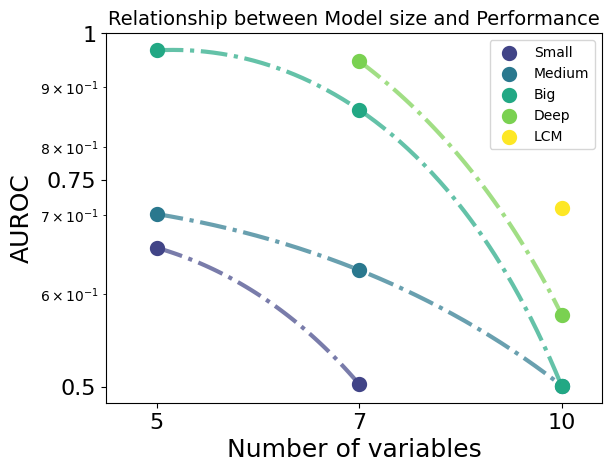

In [139]:
cm_subsection = linspace(0,1,6)
colors = iter([ cm.viridis(x) for x in cm_subsection])
colors = iter([ cm.viridis(x) for x in cm_subsection[1:]])


col = next(iter(colors))
plt.scatter(c0[0], c0[1], color =col, alpha= 1, label = "Small", linewidth= 5)
fit = get_fit(c0)
plt.plot(fit[0], fit[1], color = col, alpha= 0.7, label = "", linewidth= 3, linestyle="dashdot")


col = next(iter(colors))
plt.scatter(c1[0], c1[1], color = col, alpha= 1, label = "Medium", linewidth= 5)
fit = get_fit(c1)
plt.plot(fit[0], fit[1], color = col, alpha= 0.7, label = "", linewidth= 3, linestyle="dashdot")

col = next(iter(colors))
plt.scatter(c2[0], c2[1], color = col, alpha= 1, label = "Big", linewidth= 5)
fit = get_fit(c2)
plt.plot(fit[0], fit[1], color = col, alpha= 0.7, label = "", linewidth= 3, linestyle="dashdot")

col = next(iter(colors))
plt.scatter(c3[0], c3[1], color =col, alpha= 1, label = "Deep", linewidth= 5)
fit = get_fit(c3)
plt.plot(fit[0], fit[1], color = col, alpha= 0.7, label = "", linewidth= 3, linestyle="dashdot")

col = next(iter(colors))
plt.scatter(c4[0], c4[1], color =col, alpha=1, label = "LCM", linewidth= 5)
fit = get_fit(c4)
plt.plot(fit[0], fit[1], color = col, alpha= 0.7, label = "", linewidth= 3, linestyle="dashdot")



plt.yscale('log')
plt.xlim([0.75,3.2])

plt.xticks([1,2,3], [5,7,10])
plt.yticks([], [])

plt.yticks([0.5, 0.75, 1], [0.5, 0.75,1])


plt.legend(loc=1)
plt.xlabel("Number of variables", fontsize=18)
plt.ylabel("AUROC", fontsize=18)
plt.title("Relationship between Model size and Performance", fontsize=14)
plt.yticks(fontsize=16)
plt.xticks(fontsize=16)

plt.savefig("images/scaling.png", dpi=200)

In [141]:
corr = pd.DataFrame([[corr[x][2][1].detach().cpu().numpy(), corr[x][3][1].detach().cpu().numpy()] for x in corr.keys()], index=corr.keys() )
var = pd.DataFrame([[var[x][2][1].detach().cpu().numpy(), var[x][3][1].detach().cpu().numpy()] for x in var.keys()], index=var.keys() )
pcmci = pd.DataFrame([[pcmci[x][0][1].detach().cpu().numpy(), pcmci[x][1][1].detach().cpu().numpy()] for x in pcmci.keys()], index=pcmci.keys() )

# Exp - 4 Kuramoto

In [35]:
corr = pickle.load(open("scores/kuramoto_corr_test_auroc.p", "rb"))
var = pickle.load(open("scores/var_test_kuramoto_auroc.p", "rb"))
pcmci = pickle.load(open("scores/pcmci_test_kuramoto_auroc.p", "rb"))

In [36]:
corr = pd.DataFrame([[corr[2][1].detach().cpu().numpy()]], index=["kuramoto"] )
var = pd.DataFrame([[var[2][1].detach().cpu().numpy()]], index=["kuramoto"] )
pcmci = pd.DataFrame([[pcmci["kuramoto"][0][1].detach().cpu().numpy()]], index=["kuramoto"] )

In [37]:
maxi = pd.read_csv("scores/slurm_kura_max.csv", index_col=[0,1])
mean = pd.read_csv("scores/slurm_kura_mean.csv", index_col=[0,1])
std = pd.read_csv("scores/slurm_kura_std.csv", index_col=[0,1])

In [38]:
a = reformat_table_for_paper(std,mean, exp=3, which="Test1_Auroc").reset_index().to_latex(index=False, header= False)
for line in a[30:-26].split("\n")[:-1]:
    print(repr(line[:-1]))

'l'
'\\midrul'
'kuramoto & .825 (.025) & .905 (.053) & .852 (.076) & .954 (.01) & .888 (.07) \\'


In [39]:
a = pd.concat([corr,var, pcmci]).T.astype(float).round(3).astype(str).to_latex(index=False, header= False)
for line in a[30:-26].split("\n")[:-1]:
    print(repr(line[:-1]))

'\\midrul'
'0.628 & 0.464 & 0.523 \\'


In [40]:
a = std.reset_index().loc[[2,4,0,1,3]]
a["Test1_Auroc"] = a["Test1_Auroc"].astype(float).round(4).astype(str)
a = a.T.to_latex(index=False, header= False)
for line in a[30:-26].split("\n")[:-1]:
    print(repr(line[:-1]))

''
'\\midrul'
'mlp & unidirectional & bidirectional & convM & transformer \\'
'kuramoto & kuramoto & kuramoto & kuramoto & kuramoto \\'
'0.0248 & 0.0526 & 0.0762 & 0.0104 & 0.0704 \\'


# Zero shot: 


In [41]:
# Zero shot: 

corr1 = pickle.load(open("scores/river_corr_test_auroc.p", "rb"))
corr2 = pickle.load(open("scores/aerosol_corr_test_auroc.p", "rb"))
corr3 = pickle.load(open("scores/netsim_corr_test_auroc.p", "rb"))
var1 = pickle.load(open("scores/river_var_test_auroc.p", "rb"))
var2 = pickle.load(open("scores/aerosol_var_test_auroc.p", "rb"))
var3 = pickle.load(open("scores/netsim_var_test_auroc.p", "rb"))
pcmci1 = pickle.load(open("scores/river_pcmci_test_auroc.p", "rb"))
pcmci2 = pickle.load(open("scores/river_pcmci_test_auroc.p", "rb"))
pcmci3 = pickle.load(open("scores/netsim_pcmci_test_auroc.p", "rb"))

In [42]:
cp_ae = pd.read_csv("scores/zero_shot_aerosols.csv", index_col=0)
cp_r = pd.read_csv("scores/zero_shot_rivers.csv", index_col=0)

In [43]:
compare = pd.DataFrame(
    [[corr1[1].numpy(), corr2.numpy(), corr3[1].numpy()],
    [pcmci1[1].numpy(), pcmci2[1].numpy(), pcmci3[1].numpy()],
    [var1[1].numpy(), var2.numpy(), var3[1].numpy()]], index = ["corr", "var", "pcmci"]
).T.astype(float).round(3)

In [44]:
compare

,corr,var,pcmci
0,1.000,1.00,1.000
1,0.473,1.00,0.443
2,0.771,0.37,0.580


In [45]:
pd.concat([cp_r.T, cp_ae, cp_r.T],axis=0).reset_index(drop=True)

,MLP,uGRU,bGRU,CM,Trf
0,tensor(0.5750),tensor(1.0000),tensor(0.4000),tensor(0.5000),tensor(1.0000)
1,0.0,0.016667,0.793333,1.0,0.15
2,tensor(0.5750),tensor(1.0000),tensor(0.4000),tensor(0.5000),tensor(1.0000)


In [46]:
a = pd.concat([pd.concat([cp_r.T, cp_ae, cp_r.T],axis=0).reset_index(drop=True),compare],axis=1).to_latex(index=False)
for line in a[30:-26].split("\n")[:-1]:
    print(repr(line[:-1]))

'rul'
'MLP & uGRU & bGRU & CM & Trf & corr & var & pcmci \\'
'\\midrul'
'tensor(0.5750) & tensor(1.0000) & tensor(0.4000) & tensor(0.5000) & tensor(1.0000) & 1.000000 & 1.000000 & 1.000000 \\'
'0.000000 & 0.016667 & 0.793333 & 1.000000 & 0.150000 & 0.473000 & 1.000000 & 0.443000 \\'
'tensor(0.5750) & tensor(1.0000) & tensor(0.4000) & tensor(0.5000) & tensor(1.0000) & 0.771000 & 0.370000 & 0.580000 \\'
